# Day 6: Transfer Learning with ResNet18

Goal: fine-tune an ImageNet-pretrained ResNet18 on CIFAR-10, compare training with and without data augmentation, and create a confusion matrix.


Setup and imports

In [1]:
import os, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from torchvision.models import ResNet18_Weights
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


Download CIFAR-10

In [2]:
DATA_DIR = "./data"
train_raw = datasets.CIFAR10(root=DATA_DIR, train=True, download=True)
test_raw = datasets.CIFAR10(root=DATA_DIR, train=False, download=True)
class_names = train_raw.classes
print("Classes:", class_names)
print("Training images:", len(train_raw), "| Test images:", len(test_raw))

100%|██████████| 170M/170M [20:38<00:00, 138kB/s]


Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Training images: 50000 | Test images: 10000


Create a fixed training and validation split

In [3]:
all_indices = np.arange(len(train_raw))
train_indices, val_indices = train_test_split(
    all_indices, test_size=0.10, random_state=SEED,
    stratify=train_raw.targets
)
print("Training samples:", len(train_indices))
print("Validation samples:", len(val_indices))

Training samples: 45000
Validation samples: 5000


Image transformations

In [4]:
# Resize CIFAR-10 images to 128x128 for the pretrained ResNet18.
image_size = 128
mean = (0.485, 0.456, 0.406)
std = (0.229, 0.224, 0.225)

transform_no_aug = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])
transform_aug = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomCrop(image_size, padding=8),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])
eval_transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

train_no_aug = datasets.CIFAR10(DATA_DIR, train=True, download=False, transform=transform_no_aug)
train_aug = datasets.CIFAR10(DATA_DIR, train=True, download=False, transform=transform_aug)
eval_train = datasets.CIFAR10(DATA_DIR, train=True, download=False, transform=eval_transform)
test_dataset = datasets.CIFAR10(DATA_DIR, train=False, download=False, transform=eval_transform)

val_dataset = Subset(eval_train, val_indices)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, num_workers=2, pin_memory=True)

Build the pretrained ResNet18

In [5]:
def build_model():
    model = models.resnet18(weights=ResNet18_Weights.DEFAULT)
    model.fc = nn.Linear(model.fc.in_features, 10)
    return model.to(device)

# We fine-tune the pretrained network. The backbone uses a smaller
# learning rate than the newly added 10-class output layer.

Training and evaluation functions

In [6]:
def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()
    total_loss, correct, total = 0.0, 0, 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):
            outputs = model(images)
            loss = criterion(outputs, labels)
            if training:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, correct / total

def make_train_loader(use_augmentation):
    dataset = train_aug if use_augmentation else train_no_aug
    subset = Subset(dataset, train_indices)
    generator = torch.Generator().manual_seed(SEED)
    return DataLoader(
        subset, batch_size=64, shuffle=True, num_workers=2,
        pin_memory=True, generator=generator
    )

criterion = nn.CrossEntropyLoss()

Run the augmentation ablation

In [8]:
# The only planned difference between these runs is training augmentation.
# Both use the same split, pretrained architecture, epochs and optimizer.
EPOCHS = 5

def train_experiment(name, use_augmentation):
    set_seed(SEED)
    train_loader = make_train_loader(use_augmentation)
    model = build_model()

    backbone_params, classifier_params = [], []
    for param_name, parameter in model.named_parameters():
        if param_name.startswith("fc."):
            classifier_params.append(parameter)
        else:
            backbone_params.append(parameter)

    optimizer = torch.optim.AdamW([
        {"params": backbone_params, "lr": 1e-4},
        {"params": classifier_params, "lr": 1e-3}
    ], weight_decay=1e-4)

    history = {"train_loss": [], "train_accuracy": [],
               "val_loss": [], "val_accuracy": []}
    start = time.time()

    for epoch in range(EPOCHS):
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_acc = run_epoch(model, val_loader, criterion)
        history["train_loss"].append(tr_loss)
        history["train_accuracy"].append(tr_acc)
        history["val_loss"].append(va_loss)
        history["val_accuracy"].append(va_acc)
        print(f"{name} | Epoch {epoch+1}/{EPOCHS} | "
              f"train loss {tr_loss:.4f}, acc {tr_acc:.4f} | "
              f"val loss {va_loss:.4f}, acc {va_acc:.4f}")

    print(f"{name} training time: {(time.time()-start)/60:.1f} minutes")
    return model, history

model_no_aug, history_no_aug = train_experiment(
    "Without augmentation", use_augmentation=False
)

Without augmentation | Epoch 1/5 | train loss 0.3357, acc 0.8857 | val loss 0.2233, acc 0.9214
Without augmentation | Epoch 2/5 | train loss 0.1053, acc 0.9642 | val loss 0.2691, acc 0.9154
Without augmentation | Epoch 3/5 | train loss 0.0681, acc 0.9763 | val loss 0.2537, acc 0.9290
Without augmentation | Epoch 4/5 | train loss 0.0538, acc 0.9817 | val loss 0.2518, acc 0.9346
Without augmentation | Epoch 5/5 | train loss 0.0441, acc 0.9855 | val loss 0.2917, acc 0.9296
Without augmentation training time: 4.4 minutes


In [9]:
model_aug, history_aug = train_experiment(
    "With augmentation", use_augmentation=True
)

With augmentation | Epoch 1/5 | train loss 0.3739, acc 0.8732 | val loss 0.2330, acc 0.9178
With augmentation | Epoch 2/5 | train loss 0.1885, acc 0.9349 | val loss 0.2065, acc 0.9288
With augmentation | Epoch 3/5 | train loss 0.1422, acc 0.9521 | val loss 0.1910, acc 0.9384
With augmentation | Epoch 4/5 | train loss 0.1139, acc 0.9613 | val loss 0.1829, acc 0.9404
With augmentation | Epoch 5/5 | train loss 0.0994, acc 0.9666 | val loss 0.2241, acc 0.9310
With augmentation training time: 4.6 minutes


Compare training curves

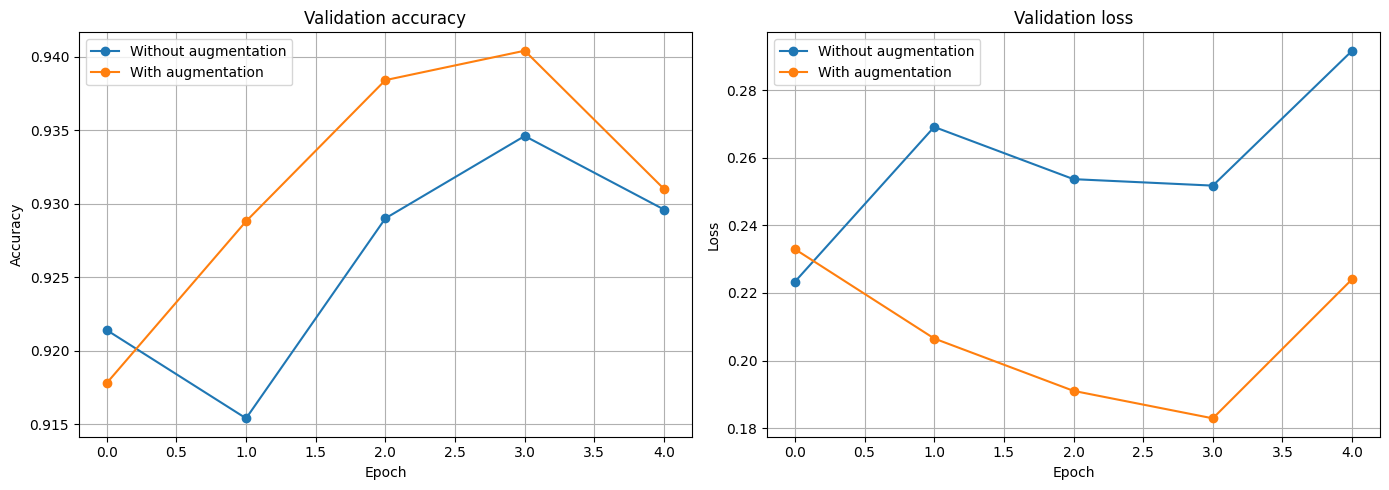

In [10]:
histories = {
    "Without augmentation": history_no_aug,
    "With augmentation": history_aug
}
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for label, history in histories.items():
    axes[0].plot(history["val_accuracy"], marker="o", label=label)
    axes[1].plot(history["val_loss"], marker="o", label=label)

axes[0].set_title("Validation accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[1].set_title("Validation loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
for ax in axes:
    ax.legend()
    ax.grid(True)
plt.tight_layout()
plt.show()

Ablation table

In [11]:
rows = []
for label, history in histories.items():
    best_idx = int(np.argmax(history["val_accuracy"]))
    rows.append({
        "Experiment": label,
        "Best validation accuracy": history["val_accuracy"][best_idx],
        "Validation loss at best epoch": history["val_loss"][best_idx],
        "Best epoch": best_idx + 1
    })

ablation_table = pd.DataFrame(rows)
display(ablation_table)

os.makedirs("results", exist_ok=True)
ablation_table.to_csv("results/ablation_table.csv", index=False)
print("Saved results/ablation_table.csv")

,Experiment,Best validation accuracy,Validation loss at best epoch,Best epoch
0,Without augmentation,0.9346,0.251755,4
1,With augmentation,0.9404,0.182893,4


Saved results/ablation_table.csv


Select a model using validation accuracy

In [12]:
best_no_aug = max(history_no_aug["val_accuracy"])
best_aug = max(history_aug["val_accuracy"])

if best_aug >= best_no_aug:
    best_model = model_aug
    selected_experiment = "With augmentation"
else:
    best_model = model_no_aug
    selected_experiment = "Without augmentation"

print("Selected model:", selected_experiment)

Selected model: With augmentation


Final test evaluation

In [13]:
# The official test set is evaluated only after model selection.
test_loss, test_accuracy = run_epoch(best_model, test_loader, criterion)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy * 100:.2f}%")

Test loss: 0.2612
Test accuracy: 92.67%


Confusion matrix and classification report

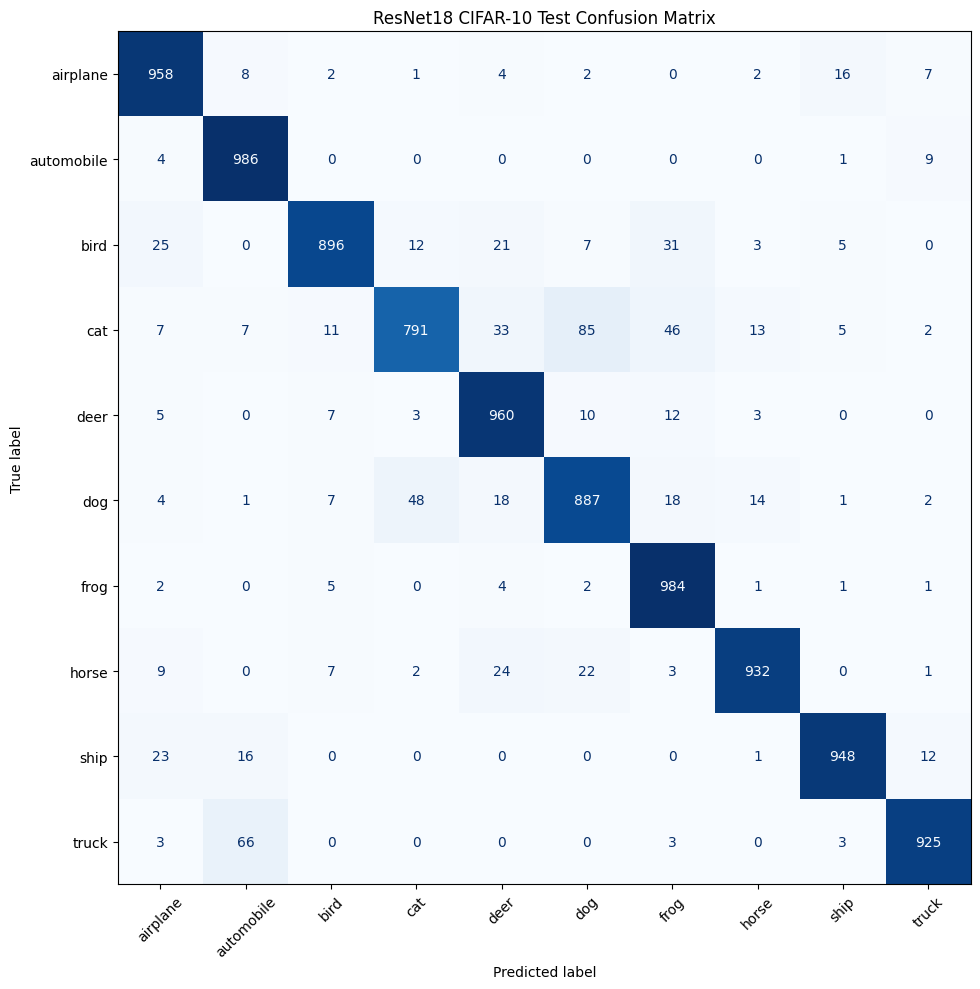

              precision    recall  f1-score   support

    airplane       0.92      0.96      0.94      1000
  automobile       0.91      0.99      0.95      1000
        bird       0.96      0.90      0.93      1000
         cat       0.92      0.79      0.85      1000
        deer       0.90      0.96      0.93      1000
         dog       0.87      0.89      0.88      1000
        frog       0.90      0.98      0.94      1000
       horse       0.96      0.93      0.95      1000
        ship       0.97      0.95      0.96      1000
       truck       0.96      0.93      0.94      1000

    accuracy                           0.93     10000
   macro avg       0.93      0.93      0.93     10000
weighted avg       0.93      0.93      0.93     10000

Saved results/confusion_matrix.png


In [14]:
best_model.eval()
all_predictions, all_labels = [], []

with torch.no_grad():
    for images, labels in test_loader:
        outputs = best_model(images.to(device, non_blocking=True))
        all_predictions.extend(outputs.argmax(1).cpu().numpy())
        all_labels.extend(labels.numpy())

cm = confusion_matrix(all_labels, all_predictions)
fig, ax = plt.subplots(figsize=(10, 10))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
plt.title("ResNet18 CIFAR-10 Test Confusion Matrix")
plt.tight_layout()
plt.savefig("results/confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

print(classification_report(all_labels, all_predictions, target_names=class_names))
print("Saved results/confusion_matrix.png")

Save the selected model

In [15]:
torch.save(best_model.state_dict(), "results/resnet18_cifar10.pth")
print("Saved results/resnet18_cifar10.pth")

Saved results/resnet18_cifar10.pth
